---
title: "L6-01 · Quantum common causes"
short_title: "Quantum common causes"
subtitle: "Bell correlations rule out a classical complete common cause under stated causal assumptions, but they are explained by a quantum common cause: the channel from the source factorizes as $\\rho_{AB|C} = \\rho_{A|C}\\,\\rho_{B|C}$ while the shared state is entangled."
description: "Derive the CHSH bound for every classical common-cause model of the Bell graph, show that a shared quantum state exceeds it, and state the quantum Reichenbach principle of Allen et al. that makes such a state a legitimate common cause."
tags: [level-6, coursebook]
---

(lesson-l6-01)=

:::{div}
:class: qcai-meta
![Level 6 icon](../../_static/icons/qicon-level-6.svg) **Level 6 · Graduate** · about 130 minutes  
**Big idea.** Bell correlations rule out a classical complete common cause under stated causal assumptions, but they are explained by a quantum common cause: the channel from the source factorizes as $\rho_{AB|C} = \rho_{A|C}\,\rho_{B|C}$ while the shared state is entangled.  
**Before this lesson.** [L5-08](#lesson-l5-08), [L4-01](#lesson-l4-01), [L4-02](#lesson-l4-02)  
**Lab.** [Entanglement and Bell tests](../../labs/06-entanglement-bell.ipynb)
:::

## What you will be able to do

- Derive the local hidden-variable factorization from the Bell graph, naming the causal assumption behind each step, and prove $|S| \le 2$ from it.
- Compute the CHSH value of a shared $|\Phi^+\rangle$ or Werner state for given measurement directions, and prove the quantum bound $|S| \le 2\sqrt{2}$.
- State the quantum Reichenbach principle of Allen et al. (operator factorization, vanishing conditional mutual information, Hilbert-space decomposition) and test it numerically on concrete channels.
- Separate what a Bell violation shows (incompatibility with a classical complete common cause under the assumptions) from what it does not (signaling, negative probabilities, or entanglement without those assumptions).

## Why this matters

Two laboratories far apart each choose a setting and record a $\pm 1$ outcome. The outcomes are correlated, and the obvious explanation is a common cause in their shared past: a source that sends each side some instructions. Causal modeling turns that explanation into a precise claim, the factorization of the joint distribution that a directed acyclic graph with a hidden common cause implies. Bell's theorem says that every model of that form obeys an inequality, and experiments with entangled particles violate it, including experiments designed to close the standard loopholes [@bell; @chsh; @hensen].

So something in the classical common-cause story must go. One can keep classical variables and add arrows (influences between the wings, or from the source to the settings), but Wood and Spekkens showed that every such classical causal explanation needs fine-tuned parameters to hide the extra influence from the statistics [@woodspekkens]. Allen and coauthors take the other route: keep the graph and change what may sit at the common cause. Their quantum version of Reichenbach's principle says exactly when a quantum system is a complete common cause, and the source of a Bell experiment passes the test [@allen]. This lesson builds both halves carefully: the classical bound with its assumptions, and the quantum common cause with its precise definition.

:::{dropdown} Key terms

**Reichenbach's principle**
: If two variables are correlated and neither causes the other, they have a common cause, and conditioning on the complete common cause makes them independent.

**Local hidden-variable model**
: A classical common-cause model of the Bell graph: $p(a,b|x,y) = \sum_\lambda p(\lambda)\, p(a|x,\lambda)\, p(b|y,\lambda)$.

**CHSH quantity**
: $S = E_{00} + E_{01} + E_{10} - E_{11}$ with $E_{xy}$ the mean of the product of the $\pm 1$ outcomes at settings $x, y$.

**Quantum common cause**
: A quantum system $C$ whose channel to $A$ and $B$ is compatible with $C$ being their complete common cause; by Allen et al. this is equivalent to $\rho_{AB|C} = \rho_{A|C}\,\rho_{B|C}$.

**Conditional operator**
: The operator $\rho_{B|A}$ that represents a channel from $A$ to $B$ (a Choi operator, normalized so that tracing out $B$ gives the identity).

**Fine-tuning**
: A conditional independence that holds only for special parameter values of a causal model, not because of the graph.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l6_01 as _lessonfigs

## Reichenbach's principle and the Bell graph

In a classical causal model the joint distribution of the variables of a directed acyclic graph factorizes into the conditional distribution of each variable given its parents [@pearlcausality], as in [L4-01](#lesson-l4-01) and [L4-02](#lesson-l4-02). Reichenbach's principle is the special case of a common cause: if $C$ is the complete common cause of $A$ and $B$, then $P(A, B|C) = P(A|C)\,P(B|C)$. For a Bell experiment the graph has settings $X, Y$, outcomes $A, B$ and a hidden source variable $\Lambda$.

```{mermaid}
graph TD
  X["setting X"] --> A["outcome A"]
  L["hidden source Lambda"] --> A
  L --> B["outcome B"]
  Y["setting Y"] --> B
```

*The Bell scenario as a causal graph. The missing arrows carry the assumptions: no arrow from the settings into the source, no arrow from one setting to the far outcome, and no arrow between the outcomes.*

:::{prf:assumption} The classical common-cause model of a Bell test
:label: asm-l6-01-bell
1. **Classical source.** The common cause is a random variable $\Lambda$ with a distribution $p(\lambda)$.
2. **Measurement independence.** The settings are statistically independent of the source: $p(\lambda|x,y) = p(\lambda)$.
3. **Locality (parental structure).** Each outcome depends only on its own setting and the source: $p(a|x,y,\lambda) = p(a|x,\lambda)$ and $p(b|a,x,y,\lambda) = p(b|a,y,\lambda)$.
4. **Complete common cause.** Given $\lambda$ and the settings, the outcomes are independent: $p(b|a,y,\lambda) = p(b|y,\lambda)$.

Together these are exactly the Markov condition for the graph above with $\Lambda$ marginalized out. Experiments argue for 2 and 3 with random setting choices at space-like separation; they cannot prove them.
:::

:::{figure} ../../_static/animations/l6_01_bell_dag.mp4
:alt: A causal graph with settings X and Y, outcomes A and B and a hidden source Lambda. The chain-rule expansion of p(a,b|x,y) is simplified in three steps as three assumptions are applied.
:width: 100%

From the chain rule to the local hidden-variable model: each simplification is licensed by one missing arrow of the graph.
:::

:::{dropdown} What the animation shows
The graph $X \to A \leftarrow \Lambda \to B \leftarrow Y$ is drawn, with a key: settings, outcomes, hidden common cause. Next to it the chain rule, which always holds, is written: $p(a,b|x,y) = \sum_\lambda p(\lambda|x,y)\,p(a|x,y,\lambda)\,p(b|a,x,y,\lambda)$. Step 1, measurement independence (no arrow into $\Lambda$ from $X$ or $Y$), turns $p(\lambda|x,y)$ into $p(\lambda)$. Step 2, locality (no arrow from $X$ to $B$ or from $Y$ to $A$), turns $p(a|x,y,\lambda)$ into $p(a|x,\lambda)$ and $p(b|a,x,y,\lambda)$ into $p(b|a,y,\lambda)$. Step 3, complete common cause ($\Lambda$ screens off $A$ from $B$), turns $p(b|a,y,\lambda)$ into $p(b|y,\lambda)$. The final formula is $\sum_\lambda p(\lambda)\,p(a|x,\lambda)\,p(b|y,\lambda)$, and the scene concludes that $|S| \le 2$ for every such model.
:::

$$
p(a,b|x,y) = \sum_\lambda p(\lambda)\, p(a|x,\lambda)\, p(b|y,\lambda)
$$ (eq-l6-01-lhv)

## The CHSH bound for every classical common cause

:::{prf:definition} CHSH quantity
:label: def-l6-01-chsh
Let $x, y \in \{0, 1\}$ and $a, b \in \{+1, -1\}$. Write $E_{xy} = \sum_{a,b} ab\, p(a,b|x,y)$ and define $S = E_{00} + E_{01} + E_{10} - E_{11}$ [@chsh].
:::

:::{prf:theorem} CHSH inequality
:label: thm-l6-01-chsh
Every distribution of the form [](#eq-l6-01-lhv) satisfies $|S| \le 2$.
:::

:::{prf:proof}
Define the local expectations $A_x(\lambda) = \sum_a a\, p(a|x,\lambda)$ and $B_y(\lambda) = \sum_b b\, p(b|y,\lambda)$, numbers in $[-1, 1]$. By [](#eq-l6-01-lhv), $E_{xy} = \sum_\lambda p(\lambda) A_x(\lambda) B_y(\lambda)$, so $S = \sum_\lambda p(\lambda)\, s(\lambda)$ with $s(\lambda) = A_0(B_0 + B_1) + A_1(B_0 - B_1)$ (arguments $\lambda$ suppressed). Then $|s(\lambda)| \le |B_0 + B_1| + |B_0 - B_1| = 2\max(|B_0|, |B_1|) \le 2$, and an average of numbers in $[-2, 2]$ lies in $[-2, 2]$. For deterministic responses ($A_x, B_y \in \{\pm 1\}$) one bracket vanishes and the other is $\pm 2$, so $S = \pm 2$ exactly; the bound is attained.
:::

:::{figure} ../../_static/animations/l6_01_deterministic_chsh.mp4
:alt: Sixteen boxes for the deterministic strategies each show S = +2 or -2. On a number line from -4 to 4 they stack at plus and minus 2, mixtures fill the band between, and the quantum value 2.83 lies outside.
:width: 100%

All 16 deterministic local strategies give $S = \pm 2$; mixing over $\lambda$ fills $[-2, 2]$ and nothing more. The shared state reaches $2\sqrt{2}$.
:::

:::{dropdown} What the animation shows
The scene writes $S = E_{00} + E_{01} + E_{10} - E_{11}$ and, for deterministic responses, $S = a_0(b_0 + b_1) + a_1(b_0 - b_1)$: one bracket is 0 and the other is $+2$ or $-2$. Sixteen boxes labeled by the sign patterns of $(a_0, a_1, b_0, b_1)$ turn into their values: eight $+2$ and eight $-2$, so $S = \pm 2$. On a number line from $-4$ to $4$ the sixteen values stack as dots at $-2$ and $+2$, and a shaded band marks $[-2, 2]$: mixtures over $\lambda$, which is every classical model. A red dot at $2\sqrt{2} \approx 2.83$ marks a shared $|\Phi^+\rangle$, and a gray dot at 4 marks the algebraic maximum.
:::

:::{prf:remark} What a violation does and does not rule out
A violation shows that no model satisfying all four assumptions reproduces the data. It does not say which assumption fails. Keeping a classical $\Lambda$ and dropping measurement independence or locality can reproduce the quantum statistics, but Wood and Spekkens proved that every classical causal model that reproduces Bell correlations must be fine-tuned: the observed no-signaling and setting-independence relations then hold only for special parameter values, not because of the graph [@woodspekkens]. The quantum common-cause model below keeps the graph and drops assumption 1 instead.
:::

## A quantum common cause exceeds the bound

Now let the source prepare a quantum state $\rho_{AB}$ and let each side measure a POVM chosen by its setting, $\{E_{a|x}\}_a$ and $\{F_{b|y}\}_b$. The Born rule replaces [](#eq-l6-01-lhv):

$$
p(a,b|x,y) = \operatorname{Tr}\big[(E_{a|x} \otimes F_{b|y})\, \rho_{AB}\big]
$$ (eq-l6-01-born)

:::{prf:proposition} CHSH value of a shared Werner state
:label: prop-l6-01-werner
Let $\rho_v = v|\Phi^+\rangle\langle\Phi^+| + (1-v) I/4$ with $|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt{2}$, and measure the $\pm 1$ observables $O(t) = \cos t\, Z + \sin t\, X$ (directions in the $x$-$z$ plane of the Bloch sphere; these Bloch angles are twice the polarizer angles of [L5-08](#lesson-l5-08), where $E = \cos 2(a - b)$). Then $E(s, t) = v\cos(s - t)$. With Alice at $t = 0, \pi/2$ and Bob at $t = \varphi, -\varphi$,

$$S(\varphi) = v\,(2\cos\varphi + 2\sin\varphi) = 2\sqrt{2}\,v\,\sin(\varphi + \pi/4).$$

For $v = 1$ this is $2\sqrt{2}\,\sin(\varphi + \pi/4)$, above 2 for every $\varphi$ strictly between $0$ and $\pi/2$ and equal to $2\sqrt{2}$ at $\varphi = \pi/4$.
:::

:::{prf:proof}
$\langle\Phi^+|Z \otimes Z|\Phi^+\rangle = \langle\Phi^+|X \otimes X|\Phi^+\rangle = 1$ and $\langle\Phi^+|Z \otimes X|\Phi^+\rangle = \langle\Phi^+|X \otimes Z|\Phi^+\rangle = 0$, while $I/4$ gives 0 for every traceless product. So $E(s, t) = v(\cos s\cos t + \sin s\sin t) = v\cos(s - t)$. The four terms are $v\cos\varphi$, $v\cos\varphi$, $v\cos(\pi/2 - \varphi) = v\sin\varphi$, and $-v\cos(\pi/2 + \varphi) = v\sin\varphi$. Finally $\cos\varphi + \sin\varphi = \sqrt{2}\sin(\varphi + \pi/4)$.
:::

:::{figure} ../../_static/animations/l6_01_quantum_chsh.mp4
:alt: A Bloch sphere with Alice's measurement arrows along z and x and Bob's two arrows opening symmetrically around z; beside it a graph of S against Bob's angle rises above the classical bound 2 to 2.83 at pi/4.
:width: 100%

Opening Bob's pair of directions by $\pm\varphi$ around $z$ traces $S(\varphi) = 2\sqrt{2}\,\sin(\varphi + \pi/4)$: above the classical bound for every $0 < \varphi < \pi/2$, maximal at $\varphi = \pi/4$.
:::

:::{dropdown} What the animation shows
A three-dimensional Bloch sphere shows Alice's two measurement directions as violet arrows along $z$ ($A_0 = Z$) and $x$ ($A_1 = X$). Bob's two directions $B_{0,1} = \cos\varphi\, Z \pm \sin\varphi\, X$ are orange arrows that start together along $z$ and open symmetrically in the $x$-$z$ plane. A graph on the right plots $S(\varphi) = 2\sqrt{2}\,\sin(\varphi + \pi/4)$ for $\varphi$ from 0 to $\pi/2$, with a dashed line at the classical bound 2 and a red dashed line at $2\sqrt{2}$. A red dot traces the curve as Bob's arrows open: it starts at 2, reaches $2\sqrt{2} \approx 2.83$ at $\varphi = \pi/4$, and returns to 2 at $\pi/2$, staying above 2 in between.
:::


In [2]:
_show(_lessonfigs.chsh_explorer())

**Explore.** Drag Bob's angle. The left panel shows the measurement directions in the $x$-$z$ plane; the right panel shows $S(\varphi)$ for visibilities $v = 1$, $0.85$ and $1/\sqrt{2}$.

:::{dropdown} What the figure shows
Left: a half circle with Alice's directions along $z$ and $x$ in violet and Bob's two directions at angles $\pm\varphi$ from $z$ in orange. Right: $S(\varphi) = 2\sqrt{2}\,v\,\sin(\varphi + \pi/4)$ for $\varphi$ from $0^\circ$ to $90^\circ$ and three visibilities, with a dotted line at the classical bound 2 and a marker at the chosen angle on the $v = 1$ curve. The $v = 1/\sqrt{2}$ curve touches 2 at $45^\circ$ and never exceeds it.
:::

:::{prf:theorem} Quantum bound on CHSH
:label: thm-l6-01-tsirelson
For every state $\rho_{AB}$ and all two-outcome measurements, the value of $S$ computed from [](#eq-l6-01-born) satisfies $|S| \le 2\sqrt{2}$. This is Tsirelson's bound [@tsirelson1980].
:::

:::{prf:proof}
The full proof is in [L5-08](#lesson-l5-08); the key step is short. By Naimark's dilation it is enough to treat projective measurements [@nielsenchuang], so $A_x = E_{+|x} - E_{-|x}$ and $B_y = F_{+|y} - F_{-|y}$ satisfy $A_x^2 = B_y^2 = I$ and $S = \operatorname{Tr}(\hat S\rho_{AB})$ with $\hat S = A_0 \otimes (B_0 + B_1) + A_1 \otimes (B_0 - B_1)$. Then $\hat S^2 = 4\,I \otimes I - [A_0, A_1] \otimes [B_0, B_1]$ (the first challenge exercise), each commutator has norm at most 2, so $\|\hat S\| \le 2\sqrt{2}$. The settings of the proposition attain it.
:::


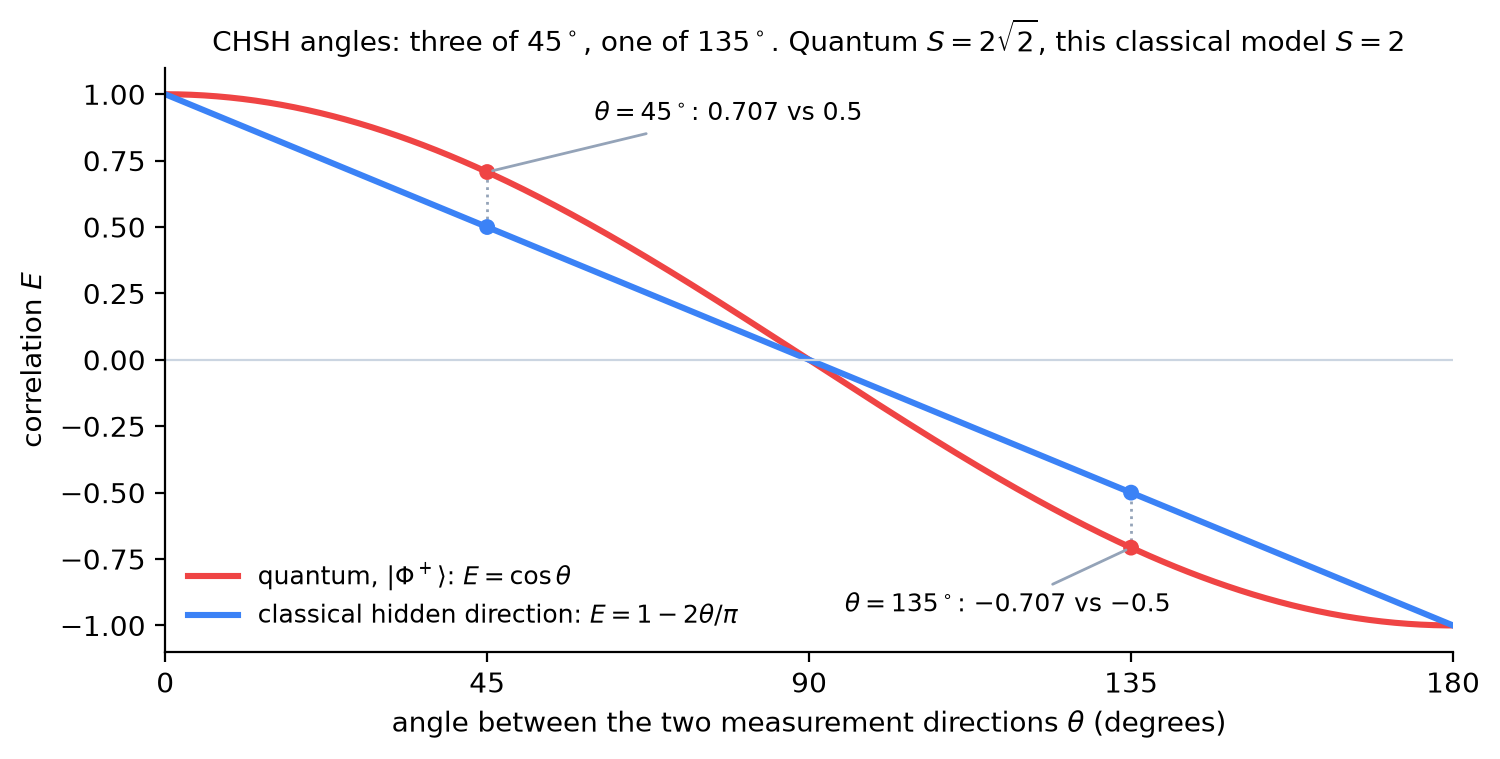

In [3]:
_show_mpl(_lessonfigs.correlation_curves())

*Why the quantum curve wins. CHSH uses relative angles $45^\circ, 45^\circ, 45^\circ$ and $135^\circ$. The classical model in which the source sends a random direction and each side reports which half-plane it lies in gives $E = 1 - 2\theta/\pi$ and $S = 3(0.5) + 0.5 = 2$; the quantum $E = \cos\theta$ gives $3(0.707) + 0.707 = 2\sqrt{2}$.*

:::{warning} No signaling, no negative probabilities
The probabilities [](#eq-l6-01-born) are ordinary non-negative probabilities, and they do not signal: $\sum_b F_{b|y} = I$ gives $p(a|x,y) = \operatorname{Tr}[E_{a|x}\rho_A]$, independent of $y$. The quantum model needs no arrow between the wings. Only assumption 1, a classical source variable that can be conditioned on, is given up.
:::

## Allen et al.: a quantum Reichenbach principle

To call the quantum source a cause, we need a quantum counterpart of the factorization $P(A,B|C) = P(A|C)P(B|C)$. Allen, Barrett, Horsman, Lee and Spekkens state it for operators that represent channels [@allen]. The channel calculus is developed in full in [L6-02](#lesson-l6-02); here is what this lesson needs.

:::{prf:definition} Conditional operator of a channel
:label: def-l6-01-cond
For a channel $\mathcal{E}: L(\mathcal{H}_C) \to L(\mathcal{H}_A \otimes \mathcal{H}_B)$ and an orthonormal basis $\{|i\rangle\}$ of $\mathcal{H}_C$, let

$$\rho_{AB|C} = \sum_{i,j} |i\rangle\langle j|_C \otimes \mathcal{E}(|i\rangle\langle j|).$$

Its marginals are $\rho_{A|C} = \operatorname{Tr}_B\, \rho_{AB|C}$ and $\rho_{B|C} = \operatorname{Tr}_A\, \rho_{AB|C}$, and products such as $\rho_{A|C}\,\rho_{B|C}$ mean $(\rho_{A|C} \otimes I_B)(\rho_{B|C} \otimes I_A)$ with the factors put in a common order. Allen et al. write the output factor first and place $C$ on the dual space $\mathcal{H}_C^{*}$; in a fixed basis their matrix has the same entries in a different factor order, so every product identity below reads the same in both conventions. Tracing out the outputs gives $I_C$, the analogue of $\sum_{a,b} P(a,b|c) = 1$.
:::

:::{prf:definition} Complete common cause (unitary compatibility)
:label: def-l6-01-ccc
A channel $\rho_{AB|C}$ is compatible with $C$ being a complete common cause of $A$ and $B$ if it has a unitary dilation with two ancillas $\lambda_A$, $\lambda_B$ prepared in independent states, such that $\lambda_A$ has no causal influence on $B$ and $\lambda_B$ has no causal influence on $A$ [@allen]. (No influence is defined through the unitary: the marginal channel to $B$ does not depend on the input at $\lambda_A$.) In words: apart from local noise, nothing but $C$ feeds both outputs.
:::

:::{prf:theorem} Quantum Reichenbach principle (Allen et al.)
:label: thm-l6-01-qrp
For a channel $\rho_{AB|C}$ the following are equivalent [@allen] (Theorems 2 and 3 in the arXiv version):

1. $\rho_{AB|C}$ is compatible with $C$ being a complete common cause of $A$ and $B$.
2. $\rho_{AB|C} = \rho_{A|C}\,\rho_{B|C}$; the two factors then commute.
3. $I(A:B|C) = 0$, the quantum conditional mutual information evaluated on the density operator $\rho_{AB|C}/d_C$.
4. $\mathcal{H}_C = \bigoplus_i \mathcal{H}_{C_i^L} \otimes \mathcal{H}_{C_i^R}$ and $\rho_{AB|C} = \sum_i \rho_{A|C_i^L} \otimes \rho_{B|C_i^R}$ with each factor a channel: the source is split, block by block, into a part that feeds $A$ and a part that feeds $B$.
:::

:::{prf:proof}
Sketch, following Allen et al. (4 implies 2): on each block the two factors act on different tensor factors of $C$, so they commute and multiply to the block. (2 implies 3 and 4) The equivalence of 3 and 4 rests on the structure theorem of Hayden, Jozsa, Petz and Winter for states with vanishing quantum conditional mutual information [@hjpw2004]; the equivalence with 2 is the contribution of Allen et al., proved in their Appendix A. (1 if and only if 2) The no-influence conditions on a unitary dilation force the factorization of its conditional operator; tracing out the ancillas keeps it. Conversely, condition 4 builds the dilation: measure which block $i$, then route $C_i^L$ to $A$ and $C_i^R$ to $B$ with local noise. Read the full proof in [@allen] before using the theorem in research.
:::

:::{prf:example} Three ways to send one qubit to two places
:label: ex-l6-01-copies
Let $C$ be a qubit. The **incoherent copy** measures $C$ in the computational basis and prepares $|00\rangle$ or $|11\rangle$: $\rho_{AB|C} = |0\rangle\langle 0|_C \otimes |00\rangle\langle 00| + |1\rangle\langle 1|_C \otimes |11\rangle\langle 11|$, which satisfies condition 2 (condition 4 with two blocks of one-dimensional factors). The **coherent copy** $\alpha|0\rangle + \beta|1\rangle \mapsto \alpha|00\rangle + \beta|11\rangle$ has $\rho_{AB|C} = |\mathrm{GHZ}\rangle\langle\mathrm{GHZ}|$ with $|\mathrm{GHZ}\rangle = |000\rangle + |111\rangle$; on the normalized operator $I(A:B|C) = 1 + 1 - 0 - 1 = 1$, so $C$ cannot be a complete common cause [@allen]. A **split source** with $C = C_L C_R$ and the identity channel $C_L \to A$, $C_R \to B$ is condition 4 with a single block. Allen et al. also note that a unitary channel needs no ancilla, so it is compatible with its whole input being the complete common cause of its outputs.
:::

:::{figure} ../../_static/animations/l6_01_quantum_reichenbach.mp4
:alt: Three small circuits from C to A and B: incoherent copy and split source pass the quantum factorization test with conditional mutual information 0, coherent copy fails with 1. The split source fed with Phi+ then gives S = 2 sqrt 2.
:width: 100%

The test $\rho_{AB|C} = \rho_{A|C}\,\rho_{B|C}$ on three channels, and the punch line: the split source passes it and, fed with $|\Phi^+\rangle$, violates CHSH.
:::

:::{dropdown} What the animation shows
The criterion $\rho_{AB|C} = \rho_{A|C}\,\rho_{B|C}$, quantum conditional independence of $A$ and $B$ given $C$, is shown at the top. Three panels each draw a node $C$, a box and two output nodes $A$ and $B$. Incoherent copy (measure, then copy): $I(A:B|C) = 0$, passes, the classical case. Coherent copy ($|i\rangle$ to $|ii\rangle$): $I(A:B|C) = 1$, fails, its Choi state is of GHZ type. Split source ($C = C_L C_R$, $C_L$ to $A$ and $C_R$ to $B$): $I(A:B|C) = 0$, passes with a single block. The other panels fade and the split source is fed the state $|\Phi^+\rangle$ on $C_L C_R$; the Born rule $p(a,b|x,y) = \operatorname{Tr}[(E_{a|x} \otimes F_{b|y})\rho_C]$ gives $S = 2\sqrt{2} > 2$. The closing line reads: quantum conditionally independent given $C$, yet Bell-violating.
:::

Put together, the Bell scenario has a causal model with the graph $C \to A$, $C \to B$: a quantum source $C = C_L C_R$ in the state $|\Phi^+\rangle$, and the split channel, which satisfies $\rho_{AB|C} = \rho_{A|C}\,\rho_{B|C}$. The outcomes obey [](#eq-l6-01-born) and reach $S = 2\sqrt{2}$, and no influence between the wings and no fine-tuning are needed. Two differences from the classical graph matter. First, the settings are not nodes: in the framework of Allen et al. a node is a place where an agent may intervene, and the setting is the choice of instrument applied there [@allen]. Second, the complete common cause is a quantum system, not a variable whose value can be conditioned on; the factorization is between operators, not between conditional probabilities. When everything is diagonal in a fixed product basis (completely dephased), the quantum condition reduces to the classical $P(A,B|C) = P(A|C)P(B|C)$ [@allen], which is why the classical principle survives as a limit.

## Beyond Bell: networks of independent sources

In the Bell graph the settings do the work. Fritz studied causal structures with several independent sources and no settings at all [@fritz2012]. In the triangle, three parties each share one source with each of the other two, and a classical model has the form $p(a,b,c) = \sum_{\alpha,\beta,\gamma} p(\alpha)p(\beta)p(\gamma)\, p(a|\beta,\gamma)\, p(b|\alpha,\gamma)\, p(c|\alpha,\beta)$. Fritz proves that quantum sources in the triangle produce distributions no such classical model reproduces, and that Bell scenarios fit into his more general framework of correlation scenarios [@fritz2012].

```{mermaid}
graph TD
  al["source alpha"] --> B["party B"]
  al --> C["party C"]
  be["source beta"] --> A["party A"]
  be --> C
  ga["source gamma"] --> A
  ga --> B
```

*The triangle network: three independent sources, each shared by two of the three parties, and no measurement settings.*

:::{note} Tools for testing causal structures with latent sources
Henson, Lal and Pusey prove that the conditional independences implied by d-separation among observed variables hold in any generalized probabilistic theory, and that beyond them theory-independent constraints remain: for example, no theory gives perfect correlation among three parties that share only bipartite sources [@hlp2014]. The inflation technique derives compatibility constraints for latent-variable structures such as the triangle [@inflation], and entropic inequalities give constraints that apply to classical and quantum sources alike [@chaves]. Bell-type and causal inequalities return in [L6-06](#lesson-l6-06).
:::

## Compute it

Classical models never exceed $|S| = 2$, deterministic strategies hit $\pm 2$, and the shared $|\Phi^+\rangle$ reaches $2\sqrt{2}$. Werner states violate the inequality exactly when $v > 1/\sqrt{2}$.


In [4]:
import itertools, math
import numpy as np
from qcai import science as s

# the 16 deterministic local strategies (a0, a1, b0, b1) in {+1, -1}^4
S_det = [a0 * (b0 + b1) + a1 * (b0 - b1) for a0, a1, b0, b1 in itertools.product([1, -1], repeat=4)]
print('deterministic strategies give S in', sorted(set(S_det)))

# random stochastic classical common-cause models: local expectations A_x(l), B_y(l) in [-1, 1]
rng = np.random.default_rng(3)
best = 0.0
for _ in range(4000):
    n = int(rng.integers(1, 6))
    p = rng.dirichlet(np.ones(n))
    A, B = rng.uniform(-1, 1, (n, 2)), rng.uniform(-1, 1, (n, 2))
    E = lambda x, y: float(np.sum(p * A[:, x] * B[:, y]))
    best = max(best, abs(E(0, 0) + E(0, 1) + E(1, 0) - E(1, 1)))
print('largest |S| in 4000 random classical models:', round(best, 4))

phi = s.dm(s.bell_state('phi+'))
S_q = s.chsh_value(phi, 0, math.pi / 2, math.pi / 4, -math.pi / 4)
print('shared |Phi+>, Alice at 0 and pi/2, Bob at +-pi/4: S =', round(S_q, 6), ' (2 sqrt 2 =', round(2 * math.sqrt(2), 6), ')')
for v in (1.0, 0.85, 1 / math.sqrt(2), 0.6):
    S_v = s.chsh_value(s.werner(v), 0, math.pi / 2, math.pi / 4, -math.pi / 4)
    print(f'Werner v = {v:.3f}: S = {S_v:.4f}   best over all settings = {s.horodecki_max_chsh(s.werner(v)):.4f}')

deterministic strategies give S in [-2, 2]
largest |S| in 4000 random classical models: 1.7308
shared |Phi+>, Alice at 0 and pi/2, Bob at +-pi/4: S = 2.828427  (2 sqrt 2 = 2.828427 )
Werner v = 1.000: S = 2.8284   best over all settings = 2.8284
Werner v = 0.850: S = 2.4042   best over all settings = 2.4042
Werner v = 0.707: S = 2.0000   best over all settings = 2.0000
Werner v = 0.600: S = 1.6971   best over all settings = 1.6971


The operator identity behind the quantum bound, and a check that the quantum model does not signal.


In [5]:
def obs(t):                                   # +-1 valued observable cos(t) Z + sin(t) X
    return math.cos(t) * s.Z + math.sin(t) * s.X

comm = lambda P, Q: P @ Q - Q @ P
A0, A1, B0, B1 = obs(0), obs(math.pi / 2), obs(math.pi / 4), obs(-math.pi / 4)
S_op = np.kron(A0, B0 + B1) + np.kron(A1, B0 - B1)
print('S^2 = 4I - [A0,A1] (x) [B0,B1]:', np.allclose(S_op @ S_op, 4 * np.eye(4) - np.kron(comm(A0, A1), comm(B0, B1))))
print('largest eigenvalue of the CHSH operator:', round(float(np.linalg.eigvalsh(S_op).max()), 6))

# no signaling: Alice's outcome distribution does not depend on Bob's setting
proj = lambda O, o: (np.eye(2) + o * O) / 2
for x, Ax in ((0, A0), (1, A1)):
    marg = [sum(np.real(np.trace(np.kron(proj(Ax, 1), proj(By, b)) @ phi)) for b in (1, -1)) for By in (B0, B1)]
    print(f'p(a=+1 | x={x}, y=0) = {marg[0]:.3f}, p(a=+1 | x={x}, y=1) = {marg[1]:.3f}')

S^2 = 4I - [A0,A1] (x) [B0,B1]: True
largest eigenvalue of the CHSH operator: 2.828427
p(a=+1 | x=0, y=0) = 0.500, p(a=+1 | x=0, y=1) = 0.500
p(a=+1 | x=1, y=0) = 0.500, p(a=+1 | x=1, y=1) = 0.500


The quantum Reichenbach test on five channels from $C$ to $AB$: the factorization gap, the conditional mutual information, and the commutator of the two factors. The last lines feed $|\Phi^+\rangle$ into the split source.


In [6]:
def choi_of(E, d):
    """sum_ij |i><j| (x) E(|i><j|): input C first, then the outputs."""
    J = 0
    for i in range(d):
        for j in range(d):
            Eij = np.zeros((d, d), dtype=complex)
            Eij[i, j] = 1
            J = J + np.kron(Eij, E(Eij))
    return J

def ptr(J, dims, keep):
    """Partial trace keeping the listed tensor factors (in order)."""
    n, L = len(dims), 'abcdefgh'
    lhs = ''.join(L[k] for k in range(n)) + ''.join(L[k].upper() if k in keep else L[k] for k in range(n))
    rhs = ''.join(L[k] for k in keep) + ''.join(L[k].upper() for k in keep)
    d = int(np.prod([dims[k] for k in keep]))
    return np.einsum(lhs + '->' + rhs, J.reshape(dims + dims)).reshape(d, d)

def allen_test(J, dc):
    """max |rho_AB|C - rho_A|C rho_B|C| and I(A:B|C) on rho_AB|C / d_C (qubit outputs, ordering C, A, B)."""
    JA = np.kron(ptr(J, [dc, 2, 2], [0, 1]), np.eye(2))
    JB = np.kron(ptr(J, [dc, 2, 2], [0, 2]), np.eye(2)).reshape(dc, 2, 2, dc, 2, 2).transpose(0, 2, 1, 3, 5, 4).reshape(J.shape)
    H = lambda r: float(-sum(w * np.log2(w) for w in np.linalg.eigvalsh(r) if w > 1e-12))
    r = J / dc
    cmi = H(ptr(r, [dc, 2, 2], [0, 1])) + H(ptr(r, [dc, 2, 2], [0, 2])) - H(r) - H(ptr(r, [dc, 2, 2], [0]))
    return float(np.abs(J - JA @ JB).max()), round(cmi, 6), float(np.abs(JA @ JB - JB @ JA).max())

iso = np.zeros((4, 2)); iso[0, 0] = iso[3, 1] = 1                       # |i> -> |ii>
G = rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)); U = np.linalg.qr(G)[0]
channels = {
    'incoherent copy':        (choi_of(lambda X: X[0, 0] * np.diag([1, 0, 0, 0]) + X[1, 1] * np.diag([0, 0, 0, 1]), 2), 2),
    'coherent copy':          (choi_of(lambda X: iso @ X @ iso.T, 2), 2),
    'split source C = CL CR': (choi_of(lambda X: X, 4), 4),
    'random unitary C -> AB': (choi_of(lambda X: U @ X @ U.conj().T, 4), 4),
    'ignore C, emit |Phi+>':  (choi_of(lambda X: np.trace(X) * phi, 2), 2),
}
for name, (J, dc) in channels.items():
    gap, cmi, com = allen_test(J, dc)
    print(f'{name:24s} factorization gap {gap:.3f}   I(A:B|C) = {cmi:.3f}   commutator {com:.1e}')

# the split source fed with |Phi+> on C = CL CR gives the Bell correlations above
J = channels['split source C = CL CR'][0]
rho_AB = ptr(np.kron(phi.T, np.eye(4)) @ J, [4, 4], [1])                 # recover the output state
print('output of the split source equals |Phi+><Phi+|:', np.allclose(rho_AB, phi),
      '  S =', round(s.chsh_value(rho_AB, 0, math.pi / 2, math.pi / 4, -math.pi / 4), 6))

incoherent copy          factorization gap 0.000   I(A:B|C) = 0.000   commutator 0.0e+00
coherent copy            factorization gap 1.000   I(A:B|C) = 1.000   commutator 0.0e+00
split source C = CL CR   factorization gap 0.000   I(A:B|C) = 0.000   commutator 0.0e+00
random unitary C -> AB   factorization gap 0.000   I(A:B|C) = -0.000   commutator 3.5e-16
ignore C, emit |Phi+>    factorization gap 0.500   I(A:B|C) = 2.000   commutator 0.0e+00
output of the split source equals |Phi+><Phi+|: True   S = 2.828427


## Worked example

:::{admonition} A Werner source at the edge of violation
:class: tip

A source emits $\rho_v = v|\Phi^+\rangle\langle\Phi^+| + (1-v)I/4$. Alice measures $Z$ or $X$; Bob measures $\cos\varphi\, Z \pm \sin\varphi\, X$. For which $v$ does some $\varphi$ violate the classical bound, and is that the same as the source being entangled?

1. By the proposition, $S(\varphi) = 2\sqrt{2}\,v\,\sin(\varphi + \pi/4)$, maximized at $\varphi = \pi/4$ with value $2\sqrt{2}\,v$.
2. Violation requires $2\sqrt{2}\,v > 2$, that is $v > 1/\sqrt{2} \approx 0.707$. For $v = 0.85$, $S = 2.40$; for $v = 1/\sqrt{2}$, $S = 2$ exactly.
3. Allowing all measurement directions does not help: the Horodecki criterion (the `horodecki_max_chsh` function of the course package) gives the same maximum $2\sqrt{2}\,v$ for this state, as the first code cell prints.
4. The Werner state is entangled for $v > 1/3$ (its concurrence is $\max(0, (3v - 1)/2)$), so for $1/3 < v \le 1/\sqrt{2}$ it is entangled yet produces no CHSH violation with any settings. Werner introduced such families and showed that some entangled members admit a local hidden-variable model for all projective measurements [@werner1989].

**Result.** CHSH is violated exactly when $v > 1/\sqrt{2}$. Between $1/3$ and $1/\sqrt{2}$ the source is entangled, but this CHSH test cannot rule out a classical common cause, so it cannot certify the entanglement.
:::

## Exercises

**1. (Core)** A source emits $\tfrac12(|00\rangle\langle 00| + |11\rangle\langle 11|)$. Both sides measure $Z$ and always agree. Does this show that the source distributes entanglement or that no classical common cause exists? Give a classical model and the maximal CHSH value of this state.

:::{dropdown} Solution
No. A classical model: $\lambda \in \{0, 1\}$ with probability $1/2$ each, and both sides output $(-1)^\lambda$ for the $Z$ setting. The correlation matrix $T_{ij} = \operatorname{Tr}[\rho\, \sigma_i \otimes \sigma_j]$ is $\mathrm{diag}(0, 0, 1)$, so the Horodecki maximum is $2\sqrt{1 + 0} = 2$: no setting choice violates CHSH. One correlation table, without incompatible settings, never tests a common-cause model.
:::

**2. (Core)** On a shared $|\Phi^+\rangle$, Alice measures $Z$ and $X$, Bob measures $\cos\varphi\, Z \pm \sin\varphi\, X$ with $\varphi = \pi/6$. Compute the four correlations and $S$.

:::{dropdown} Solution
$E(s, t) = \cos(s - t)$: $E_{00} = \cos(-\pi/6) = \sqrt3/2$, $E_{01} = \cos(\pi/6) = \sqrt3/2$, $E_{10} = \cos(\pi/2 - \pi/6) = 1/2$, $E_{11} = \cos(\pi/2 + \pi/6) = -1/2$. So $S = \sqrt3/2 + \sqrt3/2 + 1/2 + 1/2 = \sqrt3 + 1 \approx 2.732$, matching $2\sqrt{2}\,\sin(\pi/6 + \pi/4) = 2\sqrt{2}\,\sin(5\pi/12) \approx 2.732$.
:::

**3. (Stretch)** A channel ignores its input qubit $C$ and emits $|\Phi^+\rangle$ on $AB$: $\mathcal{E}(X) = \operatorname{Tr}(X)\,|\Phi^+\rangle\langle\Phi^+|$. Compute $\rho_{AB|C}$, $\rho_{A|C}$, $\rho_{B|C}$ and decide whether $C$ can be the complete common cause of $A$ and $B$. Interpret.

:::{dropdown} Solution
$\rho_{AB|C} = \sum_{i,j} |i\rangle\langle j| \otimes \operatorname{Tr}(|i\rangle\langle j|)\,\Phi^+ = I_C \otimes \Phi^+$ with $\Phi^+ = |\Phi^+\rangle\langle\Phi^+|$. Then $\rho_{A|C} = I_C \otimes I_A/2$ and $\rho_{B|C} = I_C \otimes I_B/2$, so $\rho_{A|C}\,\rho_{B|C} = I_C \otimes I/4 \ne I_C \otimes \Phi^+$. The factorization fails (the third code cell prints a gap of 0.5), so $C$ is not a complete common cause: the correlation between $A$ and $B$ comes from a source other than $C$, here the hidden preparation of $\Phi^+$. The classical analogue is a channel that ignores $C$ and emits two copies of a fresh random bit.
:::

**4. (Stretch)** Show that the quantum model [](#eq-l6-01-born) never signals: $p(a|x,y)$ does not depend on $y$ and $p(b|x,y)$ does not depend on $x$, for every state and all POVMs.

:::{dropdown} Solution
$p(a|x,y) = \sum_b \operatorname{Tr}[(E_{a|x} \otimes F_{b|y})\rho_{AB}] = \operatorname{Tr}[(E_{a|x} \otimes \sum_b F_{b|y})\rho_{AB}] = \operatorname{Tr}[(E_{a|x} \otimes I)\rho_{AB}] = \operatorname{Tr}[E_{a|x}\rho_A]$ with $\rho_A = \operatorname{Tr}_B\rho_{AB}$, because a POVM sums to the identity. This does not involve $y$. The same argument with $\sum_a E_{a|x} = I$ handles $p(b|x,y)$.
:::

**5. (Challenge)** Prove the operator identity $\hat S^2 = 4\, I \otimes I - [A_0, A_1] \otimes [B_0, B_1]$ for Hermitian $A_x, B_y$ with $A_x^2 = B_y^2 = I$, where $\hat S = A_0 \otimes (B_0 + B_1) + A_1 \otimes (B_0 - B_1)$, and show that for qubit observables in the $x$-$z$ plane the bound $2\sqrt{2}$ is reached only if both commutators have norm 2, that is, both pairs of directions are orthogonal.

:::{dropdown} Solution
Expand: $\hat S^2 = A_0^2 \otimes (B_0 + B_1)^2 + A_1^2 \otimes (B_0 - B_1)^2 + A_0A_1 \otimes (B_0 + B_1)(B_0 - B_1) + A_1A_0 \otimes (B_0 - B_1)(B_0 + B_1)$. With $A_x^2 = I$: $(B_0 + B_1)^2 + (B_0 - B_1)^2 = 2B_0^2 + 2B_1^2 = 4I$. Also $(B_0 + B_1)(B_0 - B_1) = I - B_0B_1 + B_1B_0 - I = -[B_0, B_1]$ and $(B_0 - B_1)(B_0 + B_1) = [B_0, B_1]$. So the cross terms give $-A_0A_1 \otimes [B_0, B_1] + A_1A_0 \otimes [B_0, B_1] = -[A_0, A_1] \otimes [B_0, B_1]$. For $O(s) = \cos s\, Z + \sin s\, X$, $[O(s), O(t)] = \sin(t - s)[Z, X] = 2i\sin(t - s)\,Y$, with norm $2|\sin(t - s)|$. Then $\|\hat S\|^2 = \|\hat S^2\| \le 4 + 4|\sin(s_1 - s_0)\sin(t_1 - t_0)|$, which equals 8 only if both sines have modulus 1: Alice's two directions orthogonal and Bob's two directions orthogonal, as for $Z, X$ and $\pm\pi/4$.
:::

**6. (Challenge)** For the coherent copy, compute $\rho_{A|C}$, $\rho_{B|C}$ and their product, and show the product differs from $\rho_{AB|C} = |\mathrm{GHZ}\rangle\langle\mathrm{GHZ}|$ ($|\mathrm{GHZ}\rangle = |000\rangle + |111\rangle$, order $C, A, B$). Then show that completely dephasing $C$, $A$ and $B$ in the computational basis turns it into the incoherent copy, which passes.

:::{dropdown} Solution
Tracing out $B$ from $\sum_{i,j} |i\rangle\langle j|_C \otimes |ii\rangle\langle jj|_{AB}$ keeps only $i = j$: $\rho_{A|C} = |00\rangle\langle 00| + |11\rangle\langle 11|$ on $CA$, and likewise $\rho_{B|C} = |00\rangle\langle 00| + |11\rangle\langle 11|$ on $CB$. Both are diagonal, and their product (padded) is $|000\rangle\langle 000| + |111\rangle\langle 111|$, which lacks the coherences $|000\rangle\langle 111|$ and $|111\rangle\langle 000|$ of $\rho_{AB|C}$; the largest entry of the difference is 1, as the code prints. Dephasing removes exactly those coherences and leaves $|000\rangle\langle 000| + |111\rangle\langle 111|$, the incoherent copy, which equals the product. This is the classical limit of the quantum principle: diagonal operators obey it exactly when the classical channel obeys $P(A,B|C) = P(A|C)P(B|C)$.
:::

## Check your understanding

**1. Under measurement independence, locality, a classical source, and screening off, what is the largest possible value of $|S|$?**

- **A.** $2\sqrt{2}$
- **B.** 1
- **C.** 4
- **D.** 2

:::{dropdown} Show the answer
**D. 2**

Each $s(\lambda) = A_0(B_0 + B_1) + A_1(B_0 - B_1)$ lies in $[-2, 2]$, and averaging over $\lambda$ cannot leave that interval. Deterministic strategies reach $\pm 2$.
:::

**2. In the framework of Allen et al., what must hold for a channel $\rho_{AB|C}$ when $C$ is a complete common cause of $A$ and $B$?**

- **A.** $\rho_{AB|C} = \rho_{A|C}\,\rho_{B|C}$, with commuting factors
- **B.** The output state on $AB$ must be a product state
- **C.** The channel must be unitary
- **D.** $A$ and $B$ must be uncorrelated for every input

:::{dropdown} Show the answer
**A. $\rho_{AB|C} = \rho_{A|C}\,\rho_{B|C}$, with commuting factors**

The quantum Reichenbach principle is a factorization of the conditional operator, equivalent to $I(A:B|C) = 0$ on the Choi state. It allows entangled output states, as the split source fed with $|\Phi^+\rangle$ shows.
:::

**3. A Werner state with visibility $v = 0.6$ is shared. What follows from the CHSH test?**

- **A.** The test signals between the laboratories
- **B.** No violation is possible, although the state is entangled
- **C.** The state is separable, so no violation
- **D.** A violation proves entanglement

:::{dropdown} Show the answer
**B. No violation is possible, although the state is entangled**

The maximal value is $2\sqrt{2}(0.6) \approx 1.70 < 2$, so this test cannot rule out a classical common cause, yet the state is entangled because $v > 1/3$.
:::

**4. In the DAG $X \to A \leftarrow \Lambda \to B \leftarrow Y$, which pair is d-separated by the empty set?** *(Review of [L4-02](#lesson-l4-02))*

- **A.** $A$ and $B$
- **B.** $X$ and $B$
- **C.** $\Lambda$ and $A$
- **D.** $Y$ and $B$

:::{dropdown} Show the answer
**B. $X$ and $B$**

The only path from $X$ to $B$ is $X \to A \leftarrow \Lambda \to B$, which is blocked at the unconditioned collider $A$. The pair $A, B$ is connected through the common cause $\Lambda$, and the other two pairs are joined by an arrow.
:::

## Common misconceptions

- **"A Bell violation shows that one laboratory influences the other faster than light."** The quantum model has no arrow between the wings and does not signal. The violation rules out the conjunction of the classical assumptions; the quantum common-cause model drops the assumption of a classical source instead.
- **"Quantum common causes need negative or complex probabilities."** The Born rule gives ordinary probabilities. What changes is the object at the common cause and the form of the factorization: operators, $\rho_{AB|C} = \rho_{A|C}\,\rho_{B|C}$, instead of conditional distributions.
- **"Perfect correlation in one basis certifies an entangled source."** A classical shared bit gives perfect $Z$ correlation. Certification needs incompatible settings and a violated inequality, and even then only under the causal assumptions of the test.
- **"Quantum causal models abandon Reichenbach's principle."** Allen et al. keep both parts: correlations need a causal explanation, and a complete common cause implies a factorization. The factorization is reformulated for operators and reduces to the classical one for dephased channels.

:::{caution} Scope and limits
The CHSH argument assumes measurement independence, locality, a classical complete common cause, and fair sampling of runs; experiments motivate these assumptions but cannot prove them. The quantum Reichenbach principle of Allen et al. assumes that the underlying dynamics is unitary and uses their specific definitions of no influence and dilation; theorem numbers quoted here follow the arXiv version. The simulations compute exact quantum predictions and are not experiments. The Werner-state statements use the specific CHSH form and measurements stated in the text.
:::

:::{seealso} Where this leads
The conditional operators used here are Choi operators; [L6-02](#lesson-l6-02) develops them with full conventions and proofs. [L6-03](#lesson-l6-03) turns the quantum Reichenbach principle into a Markov condition for any graph. Bell and causal inequalities return in [L6-06](#lesson-l6-06), and Lab 11 compares common-cause and cause-effect signatures of two qubits.
:::

:::{dropdown} For instructors

**Why this lesson.** Graduate students often know Bell's inequality as a slogan about nonlocality. Reading it as a theorem about one causal graph, with each assumption tied to a missing arrow, makes clear what quantum causal models change and what they keep [@bell; @woodspekkens; @allen].

**Teaching notes.**

- Before the animation, ask students to name the missing arrows of the Bell graph and which factorization step each one licenses.
- Prove the classical bound with local expectations, not only deterministic strategies; it avoids the convexity argument and generalizes to stochastic responses directly.
- Run the third code cell and ask why the random unitary passes the factorization test (no ancilla is needed, so the no-influence conditions are empty) while the coherent copy, an isometry, fails.
- Use the Werner worked example to separate three properties: entanglement, CHSH violation, and incompatibility with a classical common cause.

**Assessment.** The two core exercises check model building and computation; the stretch exercises check the factorization test and no signaling; the challenges check the operator proof of the quantum bound and the classical limit of the Allen et al. condition.

**Going further.** Read Allen et al. Section V on quantum causal models and compare with Barrett, Lorenz and Oreshkov [@barrett]. Leifer and Spekkens develop the conditional-operator formalism as quantum Bayesian inference [@leifer]. Ried et al. show that quantum interventions can distinguish common-cause from cause-effect structures in cases where classical observational data cannot [@ried2015].

:::

## References

This lesson draws on [@allen; @bell; @chsh; @woodspekkens; @fritz2012; @hlp2014; @pearlcausality; @hensen; @nielsenchuang; @inflation; @chaves; @barrett; @leifer; @ried2015; @tsirelson1980; @hjpw2004; @werner1989].

**Further reading.**

- [@allen]: Sections III and V: the quantum Reichenbach principle and quantum causal models.
- [@woodspekkens]: Why classical causal explanations of Bell correlations need fine-tuning.
- [@fritz2012]: Correlation scenarios with independent sources, including the triangle.
- [@inflation]: A general method for compatibility constraints with latent sources.

**Next:** [L6-02 · Channels in the Choi representation](#lesson-l6-02)
